In [1]:
import numpy as np
import matplotlib.pyplot as plt
import iddefix
from scipy.constants import c as c_light

## Import data & visualize the data

In [2]:
# Importing wake potential data
data_wake_potential = np.loadtxt(
    "transitionsnew_beta_wakepotential.txt", comments="#", delimiter="\t"
)

# Extracting data
data_wake_time = data_wake_potential[:, 0] * 1e-9  # [s]
data_wake_dipolar = data_wake_potential[:, 4]  # [V/pC/mm]

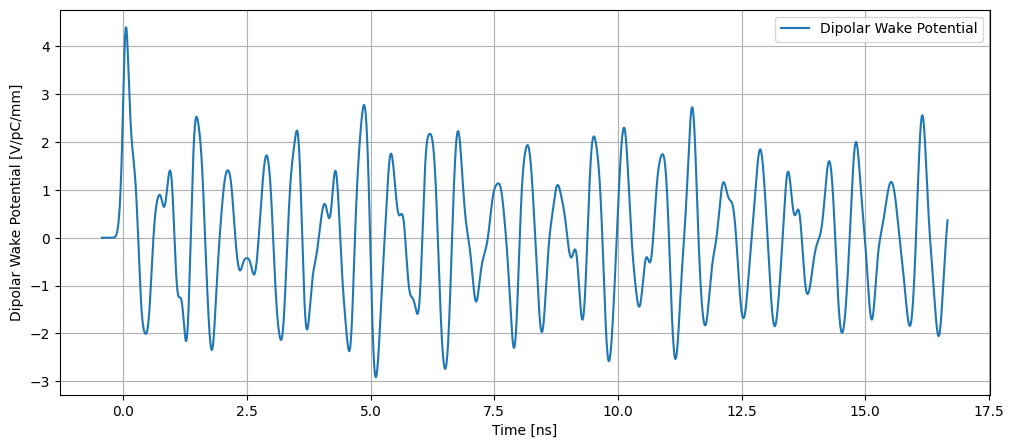

In [3]:
# Create subplots
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

# Plot data_wake_time vs data_wake_dipolar on the left
ax.plot(data_wake_time*1e9, data_wake_dipolar, label="Dipolar Wake Potential")
ax.set_xlabel("Time [ns]")
ax.set_ylabel("Dipolar Wake Potential [V/pC/mm]")
ax.grid(True)
ax.legend()

## Fitting of Wakepotential

Text(0.5, 0, 'frequency [GHz]')

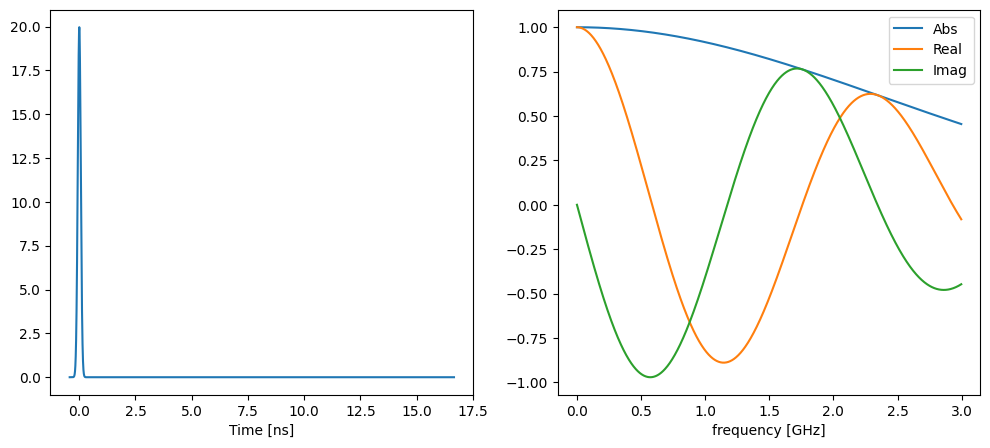

In [4]:
# Function that will be deconvolved under the hood!
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

sigma = 0.666666666666666e-10
data_time = data_wake_time
lambdas = (
    1
    / (sigma * np.sqrt(2 * np.pi))
    * np.exp(-(data_time**2) / (2 * sigma**2))
    / c_light
)

axs[0].plot(data_time * 1e9, lambdas, label="charge distribution")
axs[0].set_xlabel("Time [ns]")

ff, lambadf = iddefix.compute_fft(data_time, lambdas)
axs[1].plot(ff / 1e9, np.abs(lambadf), label="Abs")
axs[1].plot(ff / 1e9, np.real(lambadf), label="Real")
axs[1].plot(ff / 1e9, np.imag(lambadf), label="Imag")
axs[1].legend()
axs[1].set_xlabel("frequency [GHz]")

We can now use the deconvolution to observe the impedance and find the number of resonators. Notice how the impedance changes in the high frequency range due to the deconvolution:

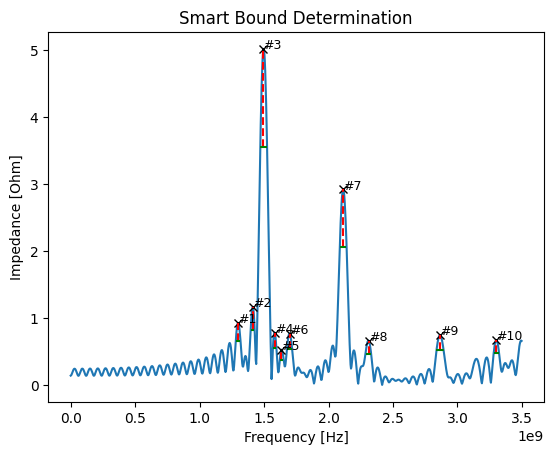

In [7]:
f, Z = iddefix.compute_deconvolution(
    data_wake_time, data_wake_dipolar, sigma=sigma, fmax=3.5e9
)

heights = np.zeros_like(Z)
heights[f < 1.5e9] = 0.8
heights[f>= 1.5e9] = 0.4
heights[f >= 2.0e9] = 0.6
bounds = iddefix.SmartBoundDetermination(f, np.abs(Z), minimum_peak_height=heights, prominence=0.1)#, distance=30)
bounds.inspect()

### Decimate the data to improve speed

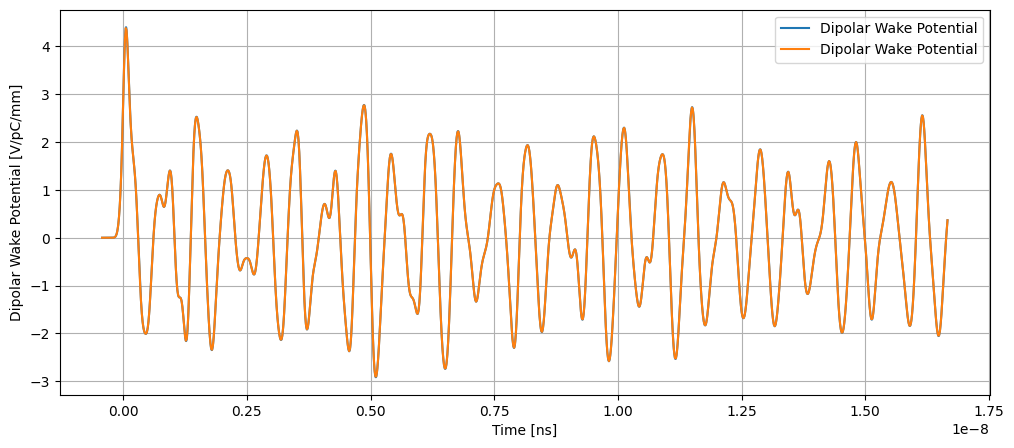

In [8]:
# Decimate wake data
x = np.linspace(data_wake_time[0], data_wake_time[-1], 1000)
y = np.interp(x, data_wake_time, data_wake_dipolar)

# Create subplots
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

# Plot data_wake_time vs data_wake_dipolar on the left
ax.plot(data_wake_time, data_wake_dipolar, label="Dipolar Wake Potential")
ax.plot(x, y, label="Dipolar Wake Potential")
ax.set_xlabel("Time [ns]")
ax.set_ylabel("Dipolar Wake Potential [V/pC/mm]")
ax.grid(True)
ax.legend()

data_wake_time = x
data_wake_dipolar = y

In [9]:
%%time
DE_model = iddefix.EvolutionaryAlgorithm(
    data_wake_time,
    data_wake_dipolar * c_light,  # remove normalization
    N_resonators=bounds.N_resonators,
    parameterBounds=bounds.parameterBounds,
    plane="transverse",
    fitFunction="wake potential",
    sigma=sigma,
    objectiveFunction=iddefix.ObjectiveFunctions.sumOfSquaredErrorReal,
)

DE_model.run_differential_evolution(
    maxiter=2000, popsize=180, tol=0.001, mutation=(0.1, 0.5), crossover_rate=0.8
)
print(DE_model.warning)

Differential Evolution:   0%|          | 0/2000 [00:00<?, ?gen/s]

Differential Evolution:  14%|█▎        | 272/2000 [09:11<58:24,  2.03s/gen, conv=103.1 %] 

[!] Warning: 16 parameter(s) have relative uncertainty >= 0.20 (max 95.33).


----------------------------------------------------------------------------
Resonator |   Rs [Ohm/m or Ohm]    |        Q         |       fres [Hz]        
----------------------------------------------------------------------------
    1     |   8.28e-01 ± 3.2e-01   |  118.58 ± 56.76  |   1.31e+09 ± 1.6e+06   
    2     |   9.34e-01 ± 3.1e+00   | 251.43 ± 956.26  |   1.42e+09 ± 4.4e+06   
    3     |   1.09e+01 ± 2.4e+00   |  133.42 ± 38.78  |   1.50e+09 ± 6.8e+05   
    4     |   6.39e-01 ± 5.3e+01   |358.12 ± 34137.86 |   1.58e+09 ± 1.1e+08   
    5     |   8.11e-01 ± 3.5e+01   |278.94 ± 14180.82 |   1.63e+09 ± 6.0e+07   
    6     |   1.75e+00 ± 4.1e+00   | 234.10 ± 721.74  |   1.69e+09 ± 8.4e+06   
    7     |   5.69e+00 ± 2.6e-01   |  158.64 ± 9.67   |   2.11e+09 ± 2.3e+05   
    8     |   1.54e+00 ± 6.8e-01   | 275.79 ± 147.81  |   2.31e+09 ± 1.2e+06   
    9     |   1.72e+00 ± 4.5e-01   |  244.35 ± 8

In [10]:
DE_model.run_minimization_algorithm()

Method for minimization : Nelder-Mead
[!] Warning: 16 parameter(s) have relative uncertainty >= 0.20 (max 105.49).


----------------------------------------------------------------------------
Resonator |   Rs [Ohm/m or Ohm]    |        Q         |       fres [Hz]        
----------------------------------------------------------------------------
    1     |   9.06e-01 ± 2.9e-01   |  106.87 ± 43.78  |   1.32e+09 ± 1.2e+06   
    2     |   8.47e-01 ± 4.1e+00   | 276.14 ± 1536.21 |   1.42e+09 ± 5.9e+06   
    3     |   1.18e+01 ± 3.2e+00   |  146.73 ± 51.83  |   1.50e+09 ± 7.2e+05   
    4     |   6.04e-01 ± 5.5e+01   |342.98 ± 36179.03 |   1.58e+09 ± 1.3e+08   
    5     |   7.33e-01 ± 3.3e+01   |254.55 ± 13951.32 |   1.63e+09 ± 7.3e+07   
    6     |   1.72e+00 ± 4.7e+00   | 243.11 ± 880.74  |   1.69e+09 ± 9.9e+06   
    7     |   5.92e+00 ± 2.6e-01   |  166.18 ± 9.51   |   2.11e+09 ± 2.1e+05   
    8     |   1.65e+00 ± 7.3e-01   | 300.23 ± 158.50  |   2.31e+09 ± 1.1e+06   
    9    

### Showing the results:

With the parameters computed by `iddefix` evolutionary algorithm, we can generate analytcally the wake potential and compare it to the original data:

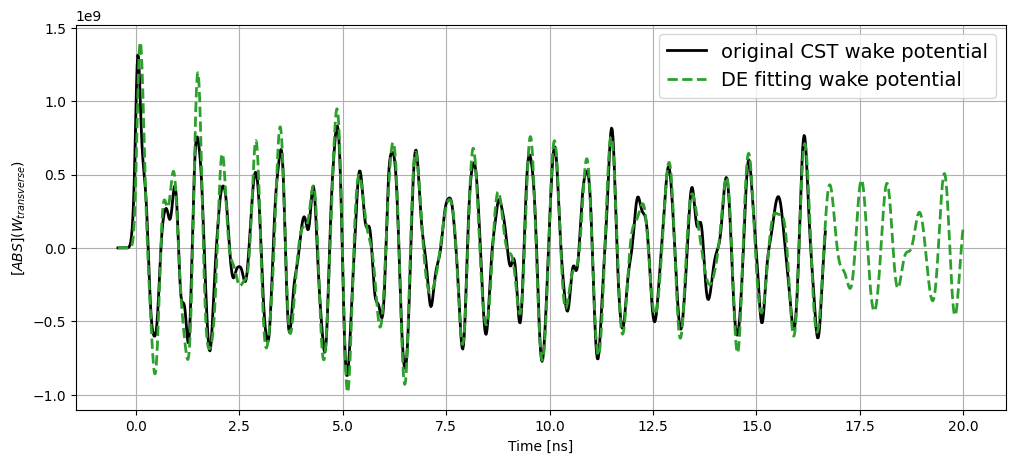

In [11]:
time = np.linspace(data_wake_time[0], 20e-9, 10000)
fig, ax0 = plt.subplots(1, 1, figsize=(12, 5))

ax0.plot(
    DE_model.time_data * 1e9,
    DE_model.wake_potential_data,
    lw=2,
    c="k",
    label="original CST wake potential",
)

ax0.plot(
    time * 1e9,
    DE_model.get_wake_potential(time, sigma=0.5e-10),
    lw=2,
    c="tab:green",
    linestyle="--",
    label="DE fitting wake potential",
)

ax0.set_xlabel("Time [ns]")
ax0.set_ylabel("$[ABS](W_{transverse})$")
ax0.legend(loc="best", fontsize=14)
ax0.grid()

## Impedance

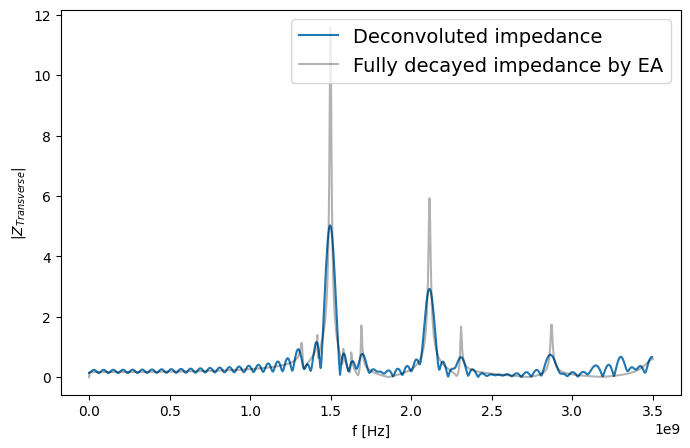

In [12]:
f, Z = iddefix.compute_deconvolution(
    data_wake_time, data_wake_dipolar, sigma=sigma, fmax=3.5e9
)
f_fd = np.linspace(0, 3.5e9, 1001)
Z_fd = DE_model.get_impedance(frequency_data=f_fd)

# Compare magnitude [ABS]
plt.figure(figsize=(8, 5))
plt.plot(f, np.abs(Z), c="tab:blue", label="Deconvoluted impedance")
plt.plot(f_fd , np.abs(Z_fd), color="k", alpha=0.3, label="Fully decayed impedance by EA")

plt.legend()
plt.xlabel("f [Hz]")
plt.ylabel("$|Z_{Transverse}|$")
plt.legend(loc="best", fontsize=14)

## Short bunch

We can also compute analytically the wake funciton from the parameters, and compare it to the wake potential. This differences are important for beam dynamic simulations, since the beam dynamic codes take as input the wake functions and not wake potentials!

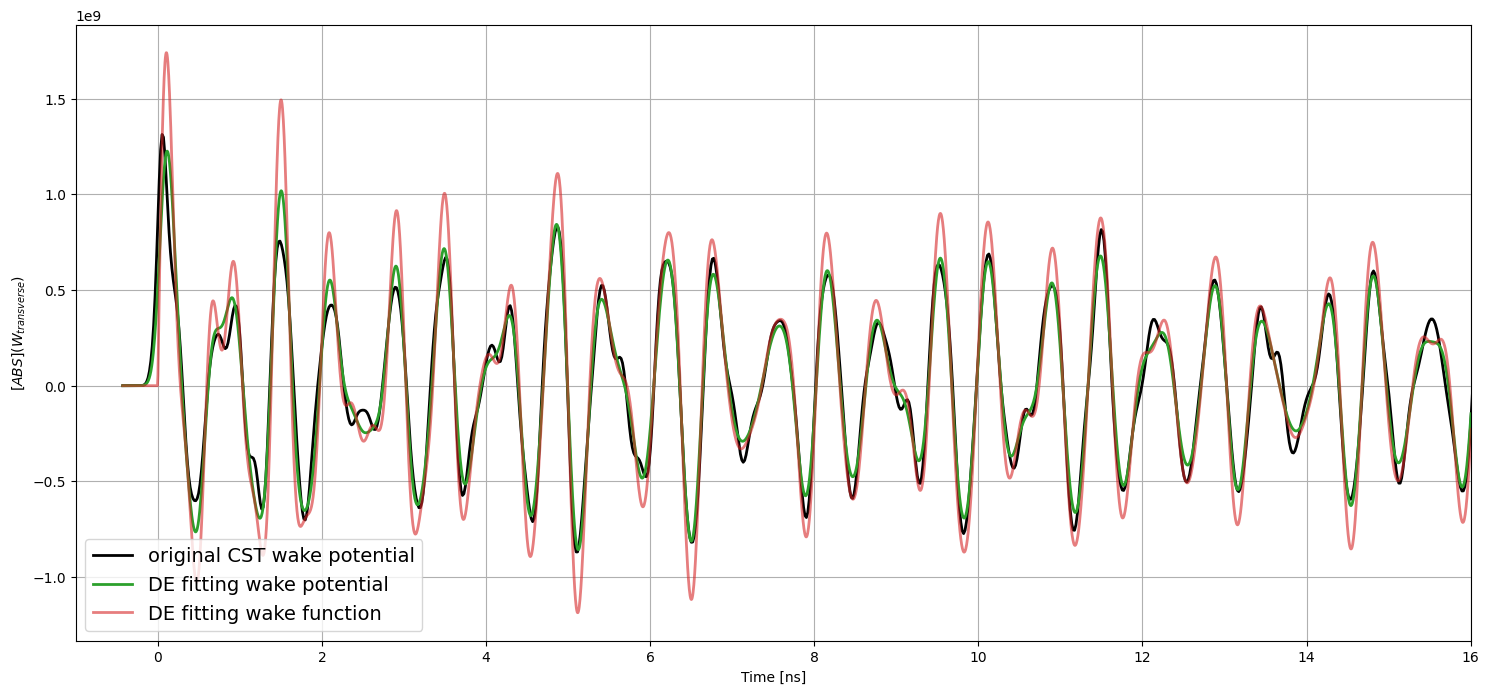

In [13]:
time = np.linspace(data_wake_time[0], 50e-9, 10000)
fig, ax0 = plt.subplots(1, 1, figsize=(18, 8))
plottime = time *1e9

ax0.plot(
    data_wake_time * 1e9,
    data_wake_dipolar * c_light,
    lw=2,
    c="k",
    label="original CST wake potential",
)

ax0.plot(
    plottime,
    DE_model.get_wake_potential(time, sigma=sigma),
    lw=2,
    c="tab:green",
    linestyle="-",
    label="DE fitting wake potential",
)

ax0.plot(
    plottime,
    DE_model.get_wake(time),
    lw=2,
    c="tab:red",
    linestyle="-",
    label="DE fitting wake function",
    alpha=0.6,
)

# ax0.plot(
#     plottime,
#     DE_model.get_wake_potential(time, sigma=5e-11),
#     lw=2,
#     c="tab:orange",
#     linestyle="-",
#     label="DE fitting wake potential at data points with sigma=5e-11",
# )

# ax0.plot(
#     plottime,
#     DE_model.get_wake_potential(time, sigma=3e-11),
#     lw=2,
#     c="tab:cyan",
#     linestyle="-",
#     label="DE fitting wake potential at data points with sigma=3e-11",
# )

# ax0.plot(
#     plottime,
#     DE_model.get_wake_potential(time, sigma=7e-11),
#     lw=2,
#     c="tab:purple",
#     linestyle="-",
#     label="DE fitting wake potential at data points with sigma=7e-11",
# )

ax0.set_xlabel("Time [ns]")
ax0.set_ylabel("$[ABS](W_{transverse})$")
ax0.legend(loc="lower left", fontsize=14)
ax0.set_xlim(-1, 16)
ax0.grid()

In [14]:
existing_data = np.loadtxt("transitionsnew_beta.txt", delimiter="\t", skiprows=1)

time_data = existing_data[:, 0]
dipolx = existing_data[:, 1]
quadx = existing_data[:, 3]

In [15]:
quady_wf = DE_model.get_wake(time) / c_light
quady_wp = DE_model.get_wake_potential(time, sigma=sigma) / c_light

In [16]:
dipoly_wf = np.loadtxt("shorterBLforCreation/transitionsnew_beta_wf.txt", delimiter="\t", skiprows=1)[:, 2]
dipoly_wp = np.loadtxt("shorterBLforCreation/transitionsnew_beta_wp.txt", delimiter="\t", skiprows=1)[:, 2]

In [17]:
data_wf = np.column_stack((time_data, dipolx, dipoly_wf, quadx, quady_wf))
data_wp = np.column_stack((time_data, dipolx, dipoly_wp, quadx, quady_wp))

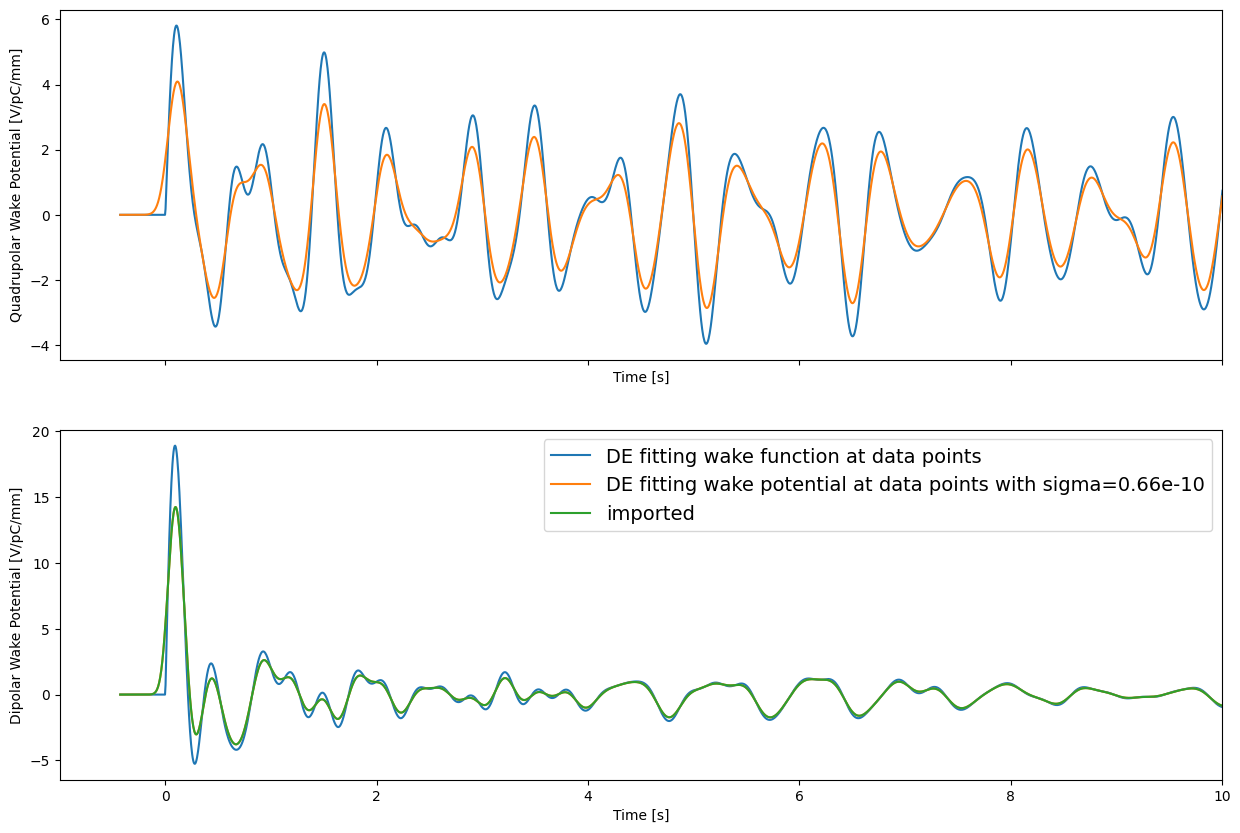

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
ax[0].plot(time_data, quady_wf, label="DE fitting wake function at data points")
ax[0].plot(time_data, quady_wp, label="DE fitting wake potential at data points with sigma=0.66e-10")
ax[0].set_xlabel("Time [s]")
ax[0].set_xlim(-1, 10)
ax[0].set_ylabel("Quadrupolar Wake Potential [V/pC/mm]")

ax[1].plot(time_data, dipoly_wf, label="DE fitting wake function at data points")
ax[1].plot(time_data, dipoly_wp, label="DE fitting wake potential at data points with sigma=0.66e-10")
ax[1].set_xlabel("Time [s]")
ax[1].set_xlim(-1, 10)
ax[1].set_ylabel("Dipolar Wake Potential [V/pC/mm]")
ax[1].legend(loc="best", fontsize=14)

plt.show()

In [21]:
np.savetxt("twoThirdBunchlenght/transitionsnew_beta_wf_q.txt", data_wf, delimiter="\t", header="time\tdipolx\tdipoly\tquadx\tquady_wf", comments="")
np.savetxt("twoThirdBunchlenght/transitionsnew_beta_wp_q.txt", data_wp, delimiter="\t", header="time\tdipolx\tdipoly\tquadx\tquady_wp", comments="")